In [70]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [71]:
df=pd.read_csv('Dataset.csv')

In [72]:
df['sales'] = pd.to_numeric(df['sales'].astype(str).str.replace(',', ''), errors='coerce')
df['profit'] = pd.to_numeric(df['profit'], errors='coerce')
df.fillna(0, inplace=True)

In [73]:
target_col = 'profit'

selected_features = ['sales', 'quantity', 'discount', 'category', 'region', 'segment']

le = LabelEncoder()
for col in ['category', 'region', 'segment']:
    df[col] = le.fit_transform(df[col].astype(str))

X = df[selected_features]
y = df[target_col]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (51325, 6)
Target shape: (51325,)


In [74]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [75]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [76]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")

MAE  (Mean Absolute Error) : 57.1382
RMSE (Root Mean Squared Error): 127.4523
R² Score                   : 0.3874


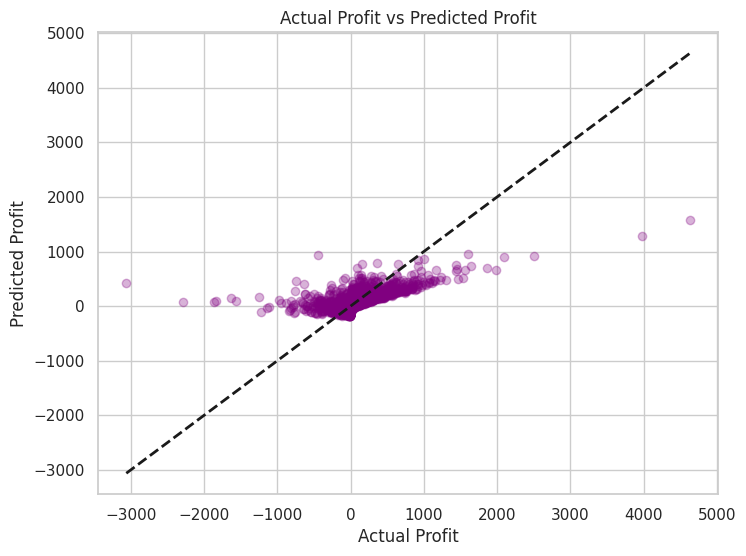

In [77]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2) # Perfect prediction line
plt.title('Actual Profit vs Predicted Profit')
plt.xlabel('Actual Profit')
plt.ylabel('Predicted Profit')
plt.show()